In [17]:
''' 
Simulation class creation for the simulation of EAB dynamic network in Maritime Canada

'''
import networkx as nx
import simpy
import pandas as pd
import random

In [18]:
import os

os.chdir('/..')
os.chdir('Users/alexp/OneDrive - University of New Brunswick/Grad Studies/Modelling_transport_pathways/Clean_data_sets')

os.getcwd()

'C:\\Users\\alexp\\OneDrive - University of New Brunswick\\Grad Studies\\Modelling_transport_pathways\\Clean_data_sets'

In [19]:
#import dataframes
#gravity_df=pd.read_csv('Campground_origin_data_raw.csv',index_col=0)
edge_df=pd.read_csv('edge_dataframe.csv',index_col=0)
node_df=pd.read_csv('node_dataframe.csv',index_col=0)
#convert dataframe to edgelist
G=nx.from_pandas_edgelist(edge_df,source='Origin',target='Campground',edge_attr=['Distance_Km'])
#add node attributes to edgelist
nx.set_node_attributes(G,dict(zip(node_df['Name'],node_df['Population'])),'Population')
nx.set_node_attributes(G, dict(zip(node_df['Name'],node_df['Sites'])),'Sites')

In [20]:
edge_df

,Campground,Origin,Distance_Km
0,ADDA Fundy Tides CG- City,Bedford,224.440514
1,ADDA Fundy Tides CG- City,Edmunston,521.343557
2,ADDA Fundy Tides CG- City,Fredericton,315.645877
3,ADDA Fundy Tides CG- City,Moncton,146.748606
4,ADDA Fundy Tides CG- City,Oromocto,300.998282
...,...,...,...
1120,Yogi Bear's Jellystone Park Camping Resort,Bedford,140.023185
1121,Yogi Bear's Jellystone Park Camping Resort,Edmunston,516.123544
1122,Yogi Bear's Jellystone Park Camping Resort,Fredericton,271.370632
1123,Yogi Bear's Jellystone Park Camping Resort,Moncton,316.453932


In [21]:
#Initial infected(I) vs susceptible(S) state 
def initial_state(G):
        state = {}
        for node in G.nodes:
            if node == 'Edmunston':
                state[node] = 'I'
            elif node == 'Bedford':
                state[node] = 'I'
            elif node == 'Fredericton':
                state[node] = 'I'
            elif node == 'Moncton':
                state[node] = 'I'
            elif node == 'Oromocto':
                state[node] = 'I'
            else:
                state[node] = 'S'
        nx.set_node_attributes(G,state,'State')
        return state

In [22]:
#test initial_state
#initial_state(G)

In [23]:
def state_transition(G, current_state):
    #The first generalization is that mostThe Þrst generalization is that a majority of campground visits involve relatively short travel distances (<100 km, which is usually a <2-h drive fromhome) Koch et al. 2012 
    next_state={}
    degree={}
    origin_degree={}
    num_inf_camper={}
    #Per capita value is a source of number of reservations taken from a national system 
    per_capita_value=0.0047
    #Firewood source(outside park:0.25, from home:0.17,cut of collected from another area:0.14)Jacobi et al. 2011, and Percent of live borers found in wood(0.23) Haack et al. 2010
    prob_infested_wood=(0.25+0.17+0.14)*0.23
    #Iterate through each node splitting the two by infected and uninfected nodes 
    for node in G.nodes:
        #if the node is infected, print the number of campers leaving the campground with infested wood/year(per capita value) is calculated, and calculate the total campground pull value from all campgrounds(in degree)
        
        if current_state[node] == 'I':
            
            #number of infected campers from campgrounds
            nx.set_node_attributes(G,{node:G.nodes[node]['Population']*(per_capita_value*prob_infested_wood)},'Infected_camper')
            Inf_camper = nx.get_node_attributes(G,'Infected_camper')
            
            #Get total campground pull from all neighbour nodes
            degree[node]= G.degree(node, weight='Campground_pull')
            nx.set_node_attributes(G, degree,'in_degree')
            num_inf_camper[node]=int(G.nodes[node]['Infected_camper'])
            
            #Get the pull of each campground using number of campsites in campground and distance between campground and origin
            node_degree={}
            for neighbor in G.neighbors(node):
                
                #defined variables X_i are the number of campsites, D_ij is the Distance between campground and origin
                X_i=G.nodes[neighbor]['Sites']
                D_ij=G.edges[neighbor,node]['Distance_Km']
                
                #Calculate pull value and normalize data using the total in-degree of nodes and load them into a dictionary of dictionary
                #dict : origin_degree = {Origin(node):{Campground(neighbor): normalized_pull}}
                pull = (X_i/D_ij)/degree[node]
                node_degree[neighbor]=pull
                origin_degree[node]=node_degree
    # create a list of randomly distributed infected campers(number of campers using k values) going from origin to a susceptible campground       
    infected=[]
    Origin_keys=[]
    Origin_values=[]
    for k, v in origin_degree.items():
        infected.append(random.choices(list(v.keys()), weights=list(v.values()), k=num_inf_camper[k]))
        
        #flatten list
        infected_flat=[val for subgroup in infected for val in subgroup]
    infected_flat.sort()  
    d = {x:infected_flat.count(x) for x in infected_flat}

    for node in G.nodes:
        if current_state[node] == 'S':
            for node,count in d.items():
                if count >1: 
                    next_state[node] = 'I'
    
    return next_state

In [24]:
#test state transition
test_state = initial_state(G)
state_transition(G, test_state)

{'BeechBrook Campground': 'I',
 'Belle Baie Park': 'I',
 'Blomidon Provincial Park': 'I',
 'Blue Heron Town Park': 'I',
 'Bouctouche Baie': 'I',
 'Brudenell River Provincial Park': 'I',
 'Cabot Beach Provincial Park': 'I',
 "Camper's City RV Resort": 'I',
 'Camping Beausejour': 'I',
 'Camping Colibri sur Mer+Motel et Camping Colibri': 'I',
 'Camping Murraywood Park': 'I',
 'Camping Pokemouche': 'I',
 'Cape Chignecto Provincial Park': 'I',
 'Cavendish Sunset Campground': 'I',
 'Cavendish-Prince Edward Island National Park': 'I',
 'Century Farm Family Campground': 'I',
 'Chignecto North-Fundy National Park': 'I',
 'Daigle Park': 'I',
 'Dollar Lake Provincial Park': 'I',
 'Dunromin Campsite and Cabins': 'I',
 'Eagle Ridge RV Park': 'I',
 'Elm River RV Park': 'I',
 "Everett's Campground": 'I',
 'Fundy Trail Campground & Cottages': 'I',
 'Gloosecap Campground & RV': 'I',
 'Great Bear Camping': 'I',
 'Halifax West KOA': 'I',
 'Harbour Light Campground': 'I',
 'Headquarters-Fundy National Par

TypeError: draw_networkx_edge_labels() missing 1 required positional argument: 'pos'

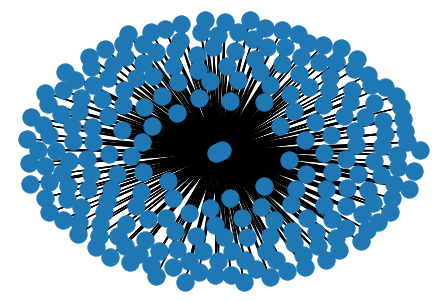

In [117]:
'Draw Graph'
#need to add positions to the edgelist of nodes
nx.draw(G)
edge_label=nx.get_edge_attributes(G,'Distance_km')
node_label=nx.get_edge_attributes(G,'campsites')
nx.draw_networkx_edge_labels(G, edge_labels=edge_label)


In [25]:
from simulation import Simulation
sim = Simulation(G, initial_state, state_transition, name='SIS model')


<AxesSubplot:title={'center':'SIS model: node state proportions'}, xlabel='Simulation step', ylabel='Proportion of nodes'>

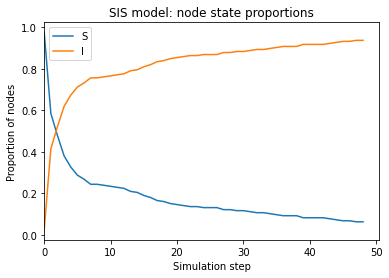

In [26]:
sim.run(48)
sim.plot()

In [35]:
sus=[]
for loc, state in sim.state().items():
    if state == 'S':
        sus.append(loc)
print(sus)

['Big Intervale-Cape Breton Highlands National Park', 'Corney Brook- Cape Breton Highlands National Park', 'Franquelin - Mount Carleton Provincial Park', 'Headwaters - Mount Carleton Provincial Park', 'Live Life in Tents', 'MacIntosh Brook-Cape Breton Highlands National Park', 'Panmure Island Provincial Park', 'Petit-Large (backcountry) - Kouchibouguac National Park', 'Raven Haven Beachside Family Park', 'Red Rock Retreat Campground', 'Upper Clements Cottages & RV Park', 'Valleyview Provincial Park', 'Williams Brook- Mount Carleton Provincial Park']


In [32]:
sus

dict_values(['I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'S', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'S', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'S', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'S', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'S', 'I', 'I', 'I', 'I', 'I', 'S', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'S', 'I', 'I', 'I', 'S', 'I', 'I', 'I', 'I', 'I', 'S', 'I', 'I', 'I', 'S', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'I', 'S', 'I', 'S', 'I', 'I', 'I', 'I

In [79]:
df = pd.DataFrame(data=sus,index=[0]).transpose()


In [81]:
df.loc[df[0] == 'S']

,0
Arm of Gold Campgrounds,S
Bayside RV Campground,S
Bear River Millyard Recreation Campground & Cottages,S
Ben's Lake Campground & Chalet,S
Big Intervale-Cape Breton Highlands National Park,S
Bridgetown Family Campground,S
Camping by the Bay,S
Castle Lake Campground & Cottages,S
Chalet and Camping De La Pointe,S
Corney Brook- Cape Breton Highlands National Park,S
